# Somatotopic Decoding — Linear SVC

**Task:** S1Map | **ROI:** Left S1 (Destrieux G_postcentral)  
**Classes:** Middle_Finger · Hand · Forearm · Arm (4-way, imbalanced)  
**Cross-validation:** Leave-One-Run-Out (LORO, 4 folds)  
**Classifier:** LinearSVC (C=3.0, OVR, `class_weight='balanced'`)  
**Features:** ROI BOLD averaged in a ±1-volume window around the HRF peak (~6 s delay)


In [1]:
import numpy as np
import pandas as pd

# Initialize random number generator for reproducibility.
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)


In [2]:
# Electrode-to-region mapping (20 electrodes → 4 body regions)
REGION_TO_ELECTRODES = {
    'Middle_Finger': ['E1', 'E2', 'E3'],
    'Hand':          ['E4', 'E5', 'E6', 'E7'],
    'Forearm':       ['E8', 'E9', 'E10', 'E11', 'E12', 'E13'],
    'Arm':           ['E14', 'E15', 'E16', 'E17', 'E18', 'E19', 'E20'],
}

    
ELECTRODE_TO_REGION = {
    electrode: region
    for region, electrodes in REGION_TO_ELECTRODES.items()
    for electrode in electrodes
}


In [4]:
# save file demonstrating the mapping from electrodes to body regions
mapping_df = pd.DataFrame(list(ELECTRODE_TO_REGION.items()), columns=['Electrode', 'Body_Region'])
mapping_df.to_csv('electrode_to_body_region_mapping.csv', index=False)

OSError: [Errno 116] Stale file handle: '.'

In [5]:
!ls

shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
ls: cannot open directory '.': Stale file handle


In [44]:
# BIDS dataset paths and experiment parameters
from pathlib import Path
import json


BIDS_ROOT = Path(r"/Volumes/T7/datasets/BIDS-somatosensory").resolve()

DERIVATIVES = BIDS_ROOT / "derivatives" / "fmriprep"

session            = "01"
task               = "S1Map"
space              = "MNI152NLin2009cAsym"
n_runs_per_subject = 4

HRF_DELAY = 6.0  # seconds from stimulus onset to HRF peak
WINDOW    = 1    # volumes to average on each side of the peak

## 1. Data Indexing (BIDS Integration)

In [45]:
import re

# Get the list of subjects that have derivatives and events files
derivative_subjects = sorted(d.name for d in DERIVATIVES.iterdir() if d.is_dir() and d.name.startswith("sub-"))

# Get the list of subjects that have events files
event_subjects = set()

for ev_path in BIDS_ROOT.rglob(f"sub-*_ses-{session}_task-{task}_run-*_events.tsv"):
    m = re.match(r"^(sub-[^_]+)_", ev_path.name)
    if m:
        event_subjects.add(m.group(1))

event_subjects = sorted(event_subjects)

subjects = sorted(set(derivative_subjects) & set(event_subjects))

print(f"Subjects in derivatives: {len(derivative_subjects)}")
print(f"Subjects in events:      {len(event_subjects)}")
print(f"Subjects included:       {len(subjects)}")
print(subjects)

Subjects in derivatives: 2
Subjects in events:      2
Subjects included:       2
['sub-p0001', 'sub-p0002']


In [46]:
# Function to get the TR (Repetition Time) for a given subject and run.
def get_tr(subject, run=1, default_tr=2.0):

    # Construct the path to the functional directory for the subject and session.
    func_dir = DERIVATIVES / f"{subject}/ses-{session}/func"

    # Construct the expected JSON filenames for the BOLD data.
    json_candidates = [
        func_dir / f"{subject}_ses-{session}_task-{task}_run-{run}_space-{space}_desc-preproc_bold.json",
        func_dir / f"{subject}_ses-{session}_task-{task}_run-{run}_desc-preproc_bold.json",
    ]

    # Check each candidate JSON file for the RepetitionTime field.
    for bold_json in json_candidates:
        # print(f"Checking for TR JSON: {bold_json}")
        if bold_json.exists():

            # Read the JSON file and extract the RepetitionTime.
            with open(bold_json, "r", encoding="utf-8") as f:
                meta = json.load(f)

            # Check if RepetitionTime is present and return it.
            if "RepetitionTime" in meta and meta["RepetitionTime"] is not None:
                return float(meta["RepetitionTime"])

            print(
                f"Warning: RepetitionTime missing in {bold_json.name} for {subject}. "
                f"Using default TR={default_tr} s."
            )
            
            return float(default_tr)

    print(
        f"Warning: No TR JSON found for {subject} (run {run}). "
        f"Using default TR={default_tr} s."
    )
    return float(default_tr)


# Get TR for each subject.
tr_by_subject = {sub: get_tr(sub, run=1, default_tr=2.0) for sub in subjects}

# Check if TR is consistent across subjects.
unique_trs = sorted(set(tr_by_subject.values()))
tr = unique_trs[0]

# Print summary of subjects and TR information.
print(f"Subjects kept: {len(subjects)}")
print(f"TR values across subjects: {unique_trs}")
if len(unique_trs) > 1:
    print("WARNING: TR is not identical across subjects; per-subject TR will be used.")
else:
    print(f"TR is consistent: {tr} s")
print(f"HRF delay: {HRF_DELAY} s  |  Window: +/-{WINDOW} vol")

Subjects kept: 2
TR values across subjects: [2.0]
TR is consistent: 2.0 s
HRF delay: 6.0 s  |  Window: +/-1 vol


## 2. Event Parsing and Label Extraction

In [47]:

# Function to load events for a given subject, including stimulation events and their corresponding regions.
def load_subject_events(subject):
    all_events = []
    required_cols = {"onset", "duration", "trial_type"}

    # Loop through each run for the subject and load the corresponding events file.
    for run in range(1, n_runs_per_subject + 1):
        events_path = BIDS_ROOT / f"{subject}" / f"ses-{session}" / "func" / f"{subject}_ses-{session}_task-{task}_run-{run}_events.tsv"
        # Check if the events file exists; raise an error if it does not.
        if not events_path.exists():
            raise FileNotFoundError(f"Missing events file: {events_path}")

        df = pd.read_csv(events_path, sep="\t")

        # Make headers consistent across files: Onset/Trial_Type -> onset/trial_type
        df.columns = [str(c).strip().lower() for c in df.columns]

        # Check if all required columns are present in the events DataFrame.
        missing = required_cols - set(df.columns)
        if missing:
            raise ValueError(
                f"{events_path.name} missing columns {sorted(missing)}. "
                f"Found {list(df.columns)}"
            )

        df["subject"] = subject
        df["run"] = run
        all_events.append(df)

    events_df = pd.concat(all_events, ignore_index=True)

    stim_events = events_df[~events_df["trial_type"].isin(["Baseline", "Jitter"])].copy()
    stim_events["region"] = stim_events["trial_type"].map(ELECTRODE_TO_REGION)

    unmapped = int(stim_events["region"].isna().sum())
    if unmapped > 0:
        bad_labels = sorted(stim_events.loc[stim_events["region"].isna(), "trial_type"].unique())
        raise ValueError(f"Unmapped trial_type values for {subject}: {bad_labels}")

    return events_df, stim_events

# preview first subject
_events_df_preview, _stim_events_preview = load_subject_events(subjects[0])
print(f"Preview subject: {subjects[0]}")
print(f"Total events: {len(_events_df_preview)}  |  Stimulation events: {len(_stim_events_preview)}")
print(f"Samples per class: {_stim_events_preview['region'].value_counts().sort_index().to_dict()}")

Preview subject: sub-p0001
Total events: 328  |  Stimulation events: 160
Samples per class: {'Arm': 56, 'Forearm': 48, 'Hand': 32, 'Middle_Finger': 24}


[get_dataset_dir] Dataset found in /Users/brunoleitao/nilearn_data/destrieux_2009


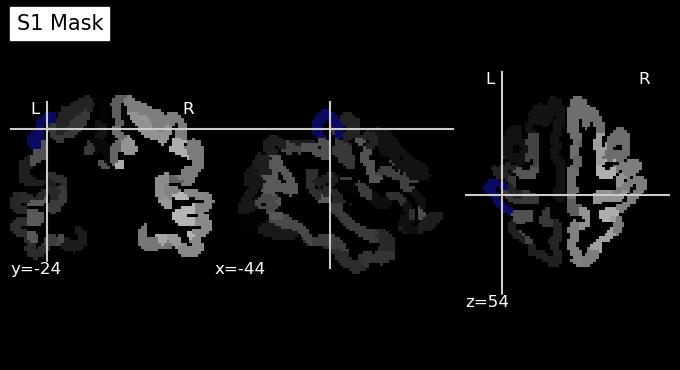

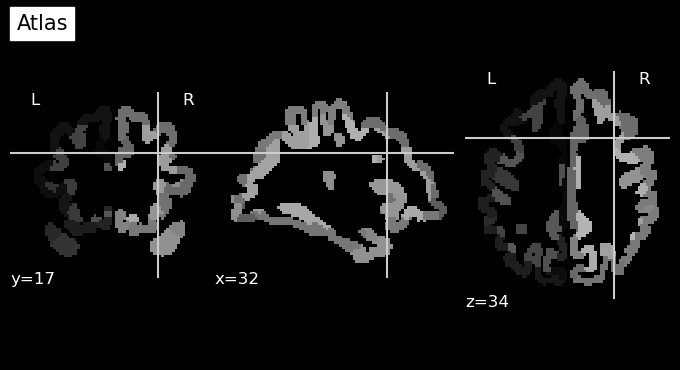

In [ ]:
from nilearn.datasets import fetch_atlas_destrieux_2009
from nilearn.image import load_img, index_img, resample_to_img, new_img_like

atlas = fetch_atlas_destrieux_2009()
atlas_img = load_img(atlas.maps)
s1_indices = [
    i for i, lab in enumerate(atlas.labels["name"])
    if "L G_postcentral" in str(lab) and i != 0
]
mask_data = np.isin(atlas_img.get_fdata(), s1_indices).astype("uint8")
s1_mask = new_img_like(atlas_img, mask_data)

# plot the S1 mask over the atlas for visual verification
from nilearn.plotting import plot_roi, plot_anat

plot_roi(s1_mask, bg_img=atlas_img, title="S1 Mask")
# plot_anat(atlas_img, title="Atlas")

## 3. The Decoder

In [69]:
from sklearn.model_selection import GridSearchCV

# Define the hyperparameters to test. 
# The prefix "clf__" tells the Pipeline to apply these to the LinearSVC step.
param_grid = {
    "clf__C": [0.01, 0.1, 1.0, 3.0, 10.0, 100.0],
    "clf__class_weight": [None, "balanced"]
}

In [ ]:
from nilearn.image import load_img, index_img, mean_img, resample_to_img
from nilearn.maskers import NiftiMasker
from nilearn import plotting
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np


RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

TOP_PERCENTILE = 50
summary_rows = []

for subject in subjects:
    print("\n" + "=" * 70)
    print(f"Processing {subject}")

    # Create subject-specific results and figures directories
    subject_results_dir = RESULTS_DIR / subject
    subject_figures_dir = subject_results_dir / "figures"
    subject_figures_dir.mkdir(parents=True, exist_ok=True)

    # Get the TR for the current subject
    tr_subject = tr_by_subject[subject]
    events_df, stim_events = load_subject_events(subject)

    # Check if the first run BOLD file exists; if not, skip this subject.

    first_run_path = (DERIVATIVES / f"{subject}/ses-{session}/func"/ f"{subject}_ses-{session}_task-{task}_run-1_space-{space}_desc-preproc_bold.nii.gz")

    print(f"Checking first run BOLD for {subject}: {first_run_path}")

    if not first_run_path.exists():
        print(f"Skipping {subject}: missing first run BOLD -> {first_run_path}")
        continue

    
    # --- Masker ---
    # Load the first run BOLD image and use it as a reference for resampling the S1 mask.
    first_run_img = load_img(str(first_run_path))
    ref_img = index_img(first_run_img, 0)

    s1_mask_resampled = resample_to_img(s1_mask, ref_img,
                                        interpolation="nearest")
    # Create a masker to extract features from the resampled image.
    masker = NiftiMasker(mask_img=s1_mask_resampled, standardize=None)
    # Fit the masker to the first run image to prepare for feature extraction.
    masker.fit(first_run_img)


    # Initialize lists to hold feature rows, labels, and group identifiers for cross-validation.
    feature_rows, labels, groups = [], [], []

    # Loop through each run for the subject and extract features based on stimulation events.
    for run in range(1, n_runs_per_subject + 1):

        # Check if the BOLD file for the current run exists; if not, skip this run.
        func_path = (DERIVATIVES / f"{subject}/ses-{session}/func"/ f"{subject}_ses-{session}_task-{task}_run-{run}_space-{space}_desc-preproc_bold.nii.gz")
        if not func_path.exists():
            print(f"  Missing BOLD run {run} for {subject}, skipping run.")
            continue

        # Load the BOLD image for the current run.
        img = load_img(str(func_path))
        run_length = img.shape[3]

        # Get the stimulation events for the current subject and run, sorted by onset time.
        run_events = stim_events[(stim_events["subject"] == subject) &(stim_events["run"] == run)].sort_values("onset")

        # Loop through each stimulation event and extract the corresponding BOLD signal.
        for _, ev in run_events.iterrows():
            # Calculate the peak volume index based on the event onset, HRF delay, and subject TR.
            peak_vol = int(np.round((float(ev["onset"]) + HRF_DELAY) / tr_subject))

            if peak_vol >= run_length:
                continue

            vols = list(range(max(0, peak_vol - WINDOW), min(run_length, peak_vol + WINDOW + 1)))

            averaged = mean_img(index_img(img, vols), copy_header=True)

            feature_rows.append(masker.transform(averaged).ravel())
            labels.append(str(ev["region"]))
            groups.append(run)

    # Check if any usable samples were extracted; if not, skip this subject.
    if len(feature_rows) == 0:
        print(f"Skipping {subject}: no usable samples after extraction.")
        continue


    # Convert the lists of feature rows, labels, and groups into NumPy arrays for further processing.
    X_features = np.vstack(feature_rows)
    y = np.asarray(labels)
    groups = np.asarray(groups)

    # Analyze the distribution of classes in the dataset.
    unique_classes = np.unique(y)
    chance_level = 1.0 / len(unique_classes)

    print(f"Feature matrix: {X_features.shape} (samples x voxels)")
    print(f"Classes: {list(unique_classes)}")
    print(f"Samples/class: { {c: int(np.sum(y == c)) for c in unique_classes} }")


    # Set up Leave-One-Run-Out cross-validation and train a Linear SVC classifier.
    logo = LeaveOneGroupOut()

    # Check if there are enough run groups for LORO.
    n_folds = logo.get_n_splits(groups=groups)

    # If there are not enough run groups, we cannot perform LORO.
    if n_folds < 2:
        print(f"Skipping {subject}: not enough run groups for LORO.")
        continue

    # Set up a Linear Support Vector Classifier with specified hyperparameters and a pipeline that includes feature scaling.
    clf = LinearSVC(
        C=3.0,
        class_weight="balanced",
        dual="auto",
        max_iter=20000,
        random_state=RANDOM_SEED,
    )

    pipe = Pipeline(steps=[("scale", StandardScaler()), ("clf", clf)])


    y_pred = np.empty_like(y, dtype=object)
    fold_acc, fold_bacc = [], []

    #store the values for each run for violin plots
    left_out_runs = []

    all_fold_shap = []
    all_fold_true = []
    all_fold_X_scaled = []

    # Loop through each fold of the Leave-One-Run-Out cross-validation, training the classifier and evaluating its performance.
    for fold_i, (train_idx, test_idx) in enumerate(logo.split(X_features, y, groups), 1):
        left_out = int(np.unique(groups[test_idx])[0])
        left_out_runs.append(left_out)

        pipe.fit(X_features[train_idx], y[train_idx])
        y_pred[test_idx] = pipe.predict(X_features[test_idx])


        acc = accuracy_score(y[test_idx], y_pred[test_idx])
        bacc = balanced_accuracy_score(y[test_idx], y_pred[test_idx])

        fold_acc.append(acc)
        fold_bacc.append(bacc)

        n_correct = int(np.sum(y[test_idx] == y_pred[test_idx]))
        n_total = len(test_idx)

        print(f"  Fold {fold_i} (left-out run {left_out}): {n_correct}/{n_total} correct")
        print(f"    Accuracy: {acc:.4f}   Balanced accuracy: {bacc:.4f}")

    mean_acc = float(np.mean(fold_acc))
    std_acc = float(np.std(fold_acc, ddof=0))
    mean_bacc = float(np.mean(fold_bacc))
    std_bacc = float(np.std(fold_bacc, ddof=0))

    summary_rows.append(
        {
            "subject": subject,
            "n_samples": int(len(y)),
            "n_voxels": int(X_features.shape[1]),
            "n_classes": int(len(unique_classes)),
            "mean_accuracy": mean_acc,
            "std_accuracy": std_acc,
            "mean_balanced_accuracy": mean_bacc,
            "std_balanced_accuracy": std_bacc,
            "chance_level": chance_level,
            "tr": tr_subject,
            "samples_per_class": str({c: int(np.sum(y == c)) for c in unique_classes}),
        }
    )

summary_df = pd.DataFrame(summary_rows).sort_values("subject").reset_index(drop=True)
summary_csv = RESULTS_DIR / "svc_multi_subject_summary.csv"
summary_df.to_csv(summary_csv, index=False)

print("\n" + "=" * 70)
print(f"Finished subjects: {len(summary_df)}")
print(f"Summary saved: {summary_csv}")

if not summary_df.empty:
    global_mean = float(summary_df["mean_balanced_accuracy"].mean())
    global_std = float(summary_df["mean_balanced_accuracy"].std(ddof=0))
    print(f"Global mean balanced accuracy: {global_mean:.4f} ± {global_std:.4f}")

summary_df


Processing sub-p0001
Checking first run BOLD for sub-p0001: /Volumes/T7/datasets/BIDS-somatosensory/derivatives/fmriprep/sub-p0001/ses-01/func/sub-p0001_ses-01_task-S1Map_run-1_space-MNI152NLin2009cAsym_desc-preproc_bold.nii.gz


/var/folders/nj/5_rdn90926779n4b6y3sbq9c0000gn/T/ipykernel_66953/984137578.py:49: FutureWarning: 'force_resample' will be set to 'True' by default in Nilearn 0.13.0.
Use 'force_resample=True' to suppress this warning.
  s1_mask_resampled = resample_to_img(s1_mask, ref_img,
/Users/brunoleitao/anaconda3/envs/mvpa/lib/python3.12/site-packages/nilearn/image/resampling.py:805: FutureWarning: From release 0.13.0 onwards, this function will, by default, copy the header of the input image to the output. Currently, the header is reset to the default Nifti1Header. To suppress this warning and use the new behavior, set `copy_header=True`.
  return resample_img(


Feature matrix: (160, 2187) (samples x voxels)
Classes: [np.str_('Arm'), np.str_('Forearm'), np.str_('Hand'), np.str_('Middle_Finger')]
Samples/class: {np.str_('Arm'): 56, np.str_('Forearm'): 48, np.str_('Hand'): 32, np.str_('Middle_Finger'): 24}
  Fold 1 (left-out run 1): 11/40 correct
    Accuracy: 0.2750   Balanced accuracy: 0.3720
  Fold 2 (left-out run 2): 17/40 correct
    Accuracy: 0.4250   Balanced accuracy: 0.4688
  Fold 3 (left-out run 3): 16/40 correct
    Accuracy: 0.4000   Balanced accuracy: 0.3378
  Fold 4 (left-out run 4): 13/40 correct
    Accuracy: 0.3250   Balanced accuracy: 0.3036

Processing sub-p0002
Checking first run BOLD for sub-p0002: /Volumes/T7/datasets/BIDS-somatosensory/derivatives/fmriprep/sub-p0002/ses-01/func/sub-p0002_ses-01_task-S1Map_run-1_space-MNI152NLin2009cAsym_desc-preproc_bold.nii.gz


/var/folders/nj/5_rdn90926779n4b6y3sbq9c0000gn/T/ipykernel_66953/984137578.py:49: FutureWarning: 'force_resample' will be set to 'True' by default in Nilearn 0.13.0.
Use 'force_resample=True' to suppress this warning.
  s1_mask_resampled = resample_to_img(s1_mask, ref_img,
/Users/brunoleitao/anaconda3/envs/mvpa/lib/python3.12/site-packages/nilearn/image/resampling.py:805: FutureWarning: From release 0.13.0 onwards, this function will, by default, copy the header of the input image to the output. Currently, the header is reset to the default Nifti1Header. To suppress this warning and use the new behavior, set `copy_header=True`.
  return resample_img(


Feature matrix: (160, 2187) (samples x voxels)
Classes: [np.str_('Arm'), np.str_('Forearm'), np.str_('Hand'), np.str_('Middle_Finger')]
Samples/class: {np.str_('Arm'): 56, np.str_('Forearm'): 48, np.str_('Hand'): 32, np.str_('Middle_Finger'): 24}
  Fold 1 (left-out run 1): 11/40 correct
    Accuracy: 0.2750   Balanced accuracy: 0.3512
  Fold 2 (left-out run 2): 22/40 correct
    Accuracy: 0.5500   Balanced accuracy: 0.5714
  Fold 3 (left-out run 3): 12/40 correct
    Accuracy: 0.3000   Balanced accuracy: 0.3497
  Fold 4 (left-out run 4): 8/40 correct
    Accuracy: 0.2000   Balanced accuracy: 0.2917

Finished subjects: 2
Summary saved: results/svc_multi_subject_summary.csv
Global mean balanced accuracy: 0.3808 ± 0.0102


,subject,n_samples,n_voxels,n_classes,mean_accuracy,std_accuracy,mean_balanced_accuracy,std_balanced_accuracy,chance_level,tr,samples_per_class
0,sub-p0001,160,2187,4,0.35625,0.059621,0.370536,0.061653,0.25,2.0,"{np.str_('Arm'): 56, np.str_('Forearm'): 48, n..."
1,sub-p0002,160,2187,4,0.33125,0.131547,0.390997,0.106902,0.25,2.0,"{np.str_('Arm'): 56, np.str_('Forearm'): 48, n..."
